# [8.3] AtP*: Fixing Attribution Patching (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part3_atp_star/8.3_AtP_from_Scratch_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part3_atp_star/8.3_AtP_from_Scratch_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-8-3) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

In [8.2] you met attribution patching (AtP): a first-order Taylor approximation that estimates the effect of patching *every* component with two forward passes and one backward
pass. On GPT-2 Small's IOI task it agreed with exact activation patching remarkably well, with a correlation of 0.94 across heads.

Here's a number that correlation hides. In this section we'll patch the value vectors of head 4.11 on 64 IOI prompts. Exact activation patching says this lowers the logit
difference by **0.30**, about 10% of the whole effect we're trying to explain, which makes 4.11 one of the most important 15 or so components out of 576. Attribution patching says
the effect is **+0.01**. If you used AtP to decide which components to look at more carefully, as people do when exact patching is too expensive, you'd rank 4.11 near the bottom
and never find out you were wrong.

That's the problem this section is about. AtP's errors aren't symmetric: a false *positive* (a component AtP says matters, but doesn't) costs you one wasted exact patch when you check it. A false *negative* (a component that matters, but AtP says doesn't) costs you a piece of the circuit, silently. Kramár, Lieberum, Shah & Nanda ([*AtP\*: An efficient and scalable method for localizing LLM behaviour to components*](https://arxiv.org/abs/2403.00745), 2024) studied these false negatives systematically, identified two mechanisms that cause them, and proposed fixes for both:

- **Attention saturation.** When a patch changes a query or key, the attention softmax can move from one saturated state to another, where the gradient says almost nothing about the size of the change. The **QK fix** recomputes the attention pattern exactly (which is cheap) and only linearises after the softmax.
- **Cancellation.** A component can affect the output through several paths whose gradients cancel at the clean input, even though the actual effects don't cancel. **GradDrop** recomputes the gradient with each layer's contribution to the backward pass removed in turn, and adds up the absolute values, so that a node with large but cancelling path effects still gets a large score.

We'll implement both, measure how much each one helps on GPT-2 Small with exact patching of all 576 attention nodes as ground truth, and find out something the paper's framing
doesn't predict: on IOI, most of the benefit comes from a third ingredient that GradDrop brings along with it. Then we'll scale up to all 36,864 MLP neurons, where exact patching
stops being cheap and a budgeted, verified search becomes the only sensible workflow.

This section assumes you've done [8.2] (we import its IOI task and metric) and [8.1].

## Content & Learning Objectives

### 1️⃣ Ground Truth and the Cost of Recall

You'll compute exact noising effects for the query, key, value and output of every attention head in GPT-2 Small (576 nodes) on IOI, the attribution-patching estimate for the same
nodes, and the paper's evaluation metric: how many nodes you need to verify, in the order a method ranks them, before you've found every important one.

> ##### Learning Objectives
>
> - Compute exact patching effects and per-prompt AtP estimates for every query, key, value and head-output node
> - Understand why recall of important nodes, not correlation, is the right way to evaluate an attribution method used for search
> - Draw recall-versus-verification-cost curves, with a random-order baseline
> - Identify AtP's false negatives on a real task

### 2️⃣ Attention Saturation and the QK Fix

You'll see the attention softmax saturate on a real head, and implement the QK fix: recompute the attention pattern exactly under a query or key patch, and linearise only from the
pattern onwards.

> ##### Learning Objectives
>
> - Understand why first-order approximations fail when a patch moves a softmax between saturated states
> - Recompute attention patterns from queries and keys, matching TransformerLens exactly
> - Implement the QK fix and measure how much it improves query and key estimates

### 3️⃣ Cancellation and GradDrop

You'll build a two-layer toy where attribution patching returns exactly zero for a component that matters, fix it with GradDrop, then run AtP* (QK fix plus GradDrop) on GPT-2 and
take it apart to see which ingredient is responsible for the improvement.

> ##### Learning Objectives
>
> - Understand how gradients through different paths can cancel even when effects don't
> - Implement GradDrop by detaching one layer's contribution on the backward pass
> - Run a component-wise ablation of AtP* rather than taking the recipe on trust
> - Explain AtP's false negatives on IOI in terms of per-prompt effects

### 4️⃣ AtP at Scale: Neurons and Verification

You'll score all 36,864 MLP neurons with one backward pass, verify a budget of them with exact patching, use group testing to check for important neurons hiding in the unverified
remainder, and bisect a suspicious group to find a neuron that AtP missed.

> ##### Learning Objectives
>
> - Apply attribution patching to MLP neurons, where exact patching is expensive
> - Design a verified search: rank cheaply, then spend a fixed budget of exact patches
> - Use group tests and adaptive bisection to find what you might have missed, and understand when they can be fooled
> - Diagnose a neuron-level false negative, and connect it to the attention-node false negatives

### ☆ Bonus

The paper's statistical false-negative bound, AtP* on other tasks and models, and further reading.

## Setup code

In [ ]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install transformer_lens==2.16.1 jaxtyping einops
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter8_automated_circuits"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [ ]:
import math
import sys
import time
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch as t
from IPython.display import display
from jaxtyping import Float, Int
from torch import Tensor
from tqdm.auto import tqdm
from transformer_lens import HookedTransformer

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter8_automated_circuits"
section = "part3_atp_star"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part3_atp_star.tests as tests
import part3_atp_star.utils as utils

# We reuse the IOI task, metric and helpers from [8.2]
from part2_attribution_patching_eap.solutions import Task, make_ioi_task, spearman_correlation

MAIN = __name__ == "__main__"

# 1️⃣ Ground Truth and the Cost of Recall

> ##### Learning Objectives
>
> - Compute exact patching effects and per-prompt AtP estimates for every query, key, value and head-output node
> - Understand why recall of important nodes, not correlation, is the right way to evaluate an attribution method used for search
> - Draw recall-versus-verification-cost curves, with a random-order baseline
> - Identify AtP's false negatives on a real task

## The model and the task

We use the same setting as [8.2]: GPT-2 Small on indirect object identification, with the **ABC corruption** (the corrupted prompt replaces all three names with unrelated names),
and the logit difference $\text{logit}(\text{IO}) - \text{logit}(\text{S})$ as the metric. We'll work in the **noising** direction: run the clean prompt, and replace one
component's activation with its value on the corrupted prompt. A component's effect is the change this causes in the logit difference, averaged over prompts.

We use 64 prompts. That's enough for stable averages, and small enough that exact patching of all 576 attention nodes takes about ten seconds on a GPU (a minute or two on a CPU).

In [ ]:
model = HookedTransformer.from_pretrained("gpt2-small", device=device)
model.requires_grad_(False)

ioi = make_ioi_task(model, 64, seed=0)
ioi = Task(ioi.clean_tokens.to(device), ioi.corrupt_tokens.to(device), ioi.answers.to(device), ioi.metric)

with t.no_grad():
    clean_metric = ioi.metric(model(ioi.clean_tokens), ioi.answers)
    corrupt_metric = ioi.metric(model(ioi.corrupt_tokens), ioi.answers)
print(f"Clean logit diff:   {clean_metric.mean():.3f}")
print(f"Corrupt logit diff: {corrupt_metric.mean():.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Clean logit diff:   2.929
Corrupt logit diff: 0.121</pre>

</details>

## Which nodes?

[8.2] patched whole head outputs. AtP*'s first fix is about queries and keys, so we need finer-grained nodes. For every attention head we'll use four:

| node | TransformerLens hook | what patching it means |
|---|---|---|
| `q` | `blocks.{l}.attn.hook_q` | the head *looks for* what it would look for on the corrupted prompt |
| `k` | `blocks.{l}.attn.hook_k` | each position *advertises* what it would advertise on the corrupted prompt |
| `v` | `blocks.{l}.attn.hook_v` | each position *sends* what it would send on the corrupted prompt |
| `z` | `blocks.{l}.attn.hook_z` | the head's output (before $W_O$) is what it would be on the corrupted prompt |

Each node is patched at all sequence positions at once. With 12 layers and 12 heads that's $4 \times 144 = 576$ nodes. We'll store everything as tensors with leading dimensions
`(kind, layer, head)`, where `kind` indexes `["q", "k", "v", "z"]`.

Here's a helper which caches all four node types plus the attention patterns (we'll need those in section 2️⃣) for a batch of prompts.

In [ ]:
KINDS = ["q", "k", "v", "z"]


def node_hook_names(n_layers: int) -> list[str]:
    return [f"blocks.{layer}.attn.hook_{kind}" for layer in range(n_layers) for kind in KINDS + ["pattern"]]


@t.no_grad()
def cache_nodes(model: HookedTransformer, tokens: Int[Tensor, "batch seq"]) -> dict[str, Tensor]:
    names = set(node_hook_names(model.cfg.n_layers))
    _, cache = model.run_with_cache(tokens, names_filter=lambda name: name in names)
    return {name: cache[name] for name in names}

In [ ]:
clean_cache = cache_nodes(model, ioi.clean_tokens)
corrupt_cache = cache_nodes(model, ioi.corrupt_tokens)
print(clean_cache["blocks.0.attn.hook_q"].shape, clean_cache["blocks.0.attn.hook_pattern"].shape)

### Exercise - exact patching for every node

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement `exact_node_effects`. For every kind, layer and head, run the clean prompts with that head's activation (at hook `blocks.{layer}.attn.hook_{kind}`, all positions, only
that head's slice of the head dimension) replaced by its corrupted value, and record the change in the per-prompt metric. If `per_prompt` is true, return the effects with shape
`(4, n_layers, n_heads, batch)`; otherwise average over prompts and return `(4, n_layers, n_heads)`.

This is 576 forward passes. Don't try to vectorise across heads; a simple loop is fine (and it's exactly the cost that attribution methods are trying to avoid!).

In [ ]:
@t.no_grad()
def exact_node_effects(
    model: HookedTransformer,
    task: Task,
    clean_cache: dict[str, Tensor],
    corrupt_cache: dict[str, Tensor],
    per_prompt: bool = False,
) -> Tensor:
    """Exact noising effect of every (kind, layer, head) node, either per prompt or averaged over prompts."""
    raise NotImplementedError()


tests.test_exact_node_effects(exact_node_effects, cache_nodes, model, ioi)

<details>
<summary>Hint</summary>

Write a hook function that sets `act[:, :, head] = corrupt_cache[name][:, :, head]` (the activations have shape `(batch, seq, n_heads, d_head)`) and pass it to
`model.run_with_hooks`. Remember to bind `head` and `name` as default arguments if you define the hook inside the loop, or Python's late binding will give every hook the last
values.
</details>


<details><summary>Solution</summary>

```python
@t.no_grad()
def exact_node_effects(
    model: HookedTransformer,
    task: Task,
    clean_cache: dict[str, Tensor],
    corrupt_cache: dict[str, Tensor],
    per_prompt: bool = False,
) -> Tensor:
    """Exact noising effect of every (kind, layer, head) node, either per prompt or averaged over prompts."""
    n_layers, n_heads = model.cfg.n_layers, model.cfg.n_heads
    clean = task.metric(model(task.clean_tokens), task.answers)
    effects = t.zeros(len(KINDS), n_layers, n_heads, len(task), device=clean.device)
    for k, kind in enumerate(KINDS):
        for layer in range(n_layers):
            name = f"blocks.{layer}.attn.hook_{kind}"
            for head in range(n_heads):

                def patch(act: Tensor, hook, head=head, name=name) -> Tensor:
                    act[:, :, head] = corrupt_cache[name][:, :, head]
                    return act

                patched = task.metric(model.run_with_hooks(task.clean_tokens, fwd_hooks=[(name, patch)]), task.answers)
                effects[k, layer, head] = patched - clean
    return effects if per_prompt else effects.mean(-1)
```
</details>

In [ ]:
t0 = time.time()
exact_per_prompt = exact_node_effects(model, ioi, clean_cache, corrupt_cache, per_prompt=True)
exact = exact_per_prompt.mean(-1).cpu()
print(f"Exact patching of 576 nodes took {time.time() - t0:.1f}s")

names = utils.flat_node_names(model.cfg.n_layers, model.cfg.n_heads)
top = exact.flatten().abs().argsort(descending=True)[:10]
print("\nLargest exact effects:")
for i in top.tolist():
    print(f"  {names[i]:>6}: {exact.flatten()[i]:+.3f}")

<details>
<summary>Expected output</summary>

The time will vary with your hardware.

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Exact patching of 576 nodes took 9.5s

Largest exact effects:
   q10.7: +1.842
   k10.7: +1.834
   z10.7: +1.401
   v10.7: +1.328
  q11.10: +1.238
  k11.10: +1.162
    v8.6: -1.140
    z8.6: -1.138
   v8.10: -0.899
   z8.10: -0.898</pre>

</details>

<details>
<summary>Help - what are these heads?</summary>

These are familiar from [1.4.1] and [8.1]. 10.7 and 11.10 are the **negative name movers** (they copy-suppress the indirect object, so knocking them out *raises* the logit
difference, hence the positive effects). 8.6 and 8.10 are **S-inhibition heads** (they move the information "S is duplicated" to the final position). Notice that for the name
movers, the query and key effects are *larger* than the output effect: patching a key or query changes where the head attends, which changes everything it writes.
</details>

## Attribution patching, per prompt

Now the cheap estimate. For a node with clean activation $a$ and corrupted activation $a'$, attribution patching estimates the effect on prompt $i$ as

$$
\hat{c}_{\text{AtP}}(n; i) = (a'_i - a_i) \cdot \frac{\partial M_i}{\partial a_i}\bigg|_{\text{clean}}
$$

where $M_i$ is the metric on prompt $i$. We'll keep the per-prompt estimates rather than averaging straight away; it'll matter in section 3️⃣.

To get per-prompt gradients from a single backward pass, differentiate the **sum** of the per-prompt metric: since prompt $i$'s activations only affect prompt $i$'s metric,
$\partial (\sum_j M_j) / \partial a_i = \partial M_i / \partial a_i$.

### Exercise - gradients with respect to every node

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement `node_gradients`, which runs the clean prompts once and returns the gradient of the summed metric with respect to every activation named in `node_hook_names` (queries,
keys, values, head outputs and attention patterns for every layer), as a dict from hook name to gradient tensor.

Ignore the `drop_layer` argument for now; you'll come back to it in section 3️⃣. (If you'd like to implement it now: when `drop_layer` is an integer, the forward pass should be
unchanged, but no gradient should flow back through that layer's attention output or MLP output into the residual stream. You can do this with hooks on
`blocks.{drop_layer}.hook_attn_out` and `blocks.{drop_layer}.hook_mlp_out` that return `act.detach()`.)

The model's parameters don't require gradients, so you need to make the cached activations themselves require gradients. A hook can do this: `act.requires_grad_(True)` and
`act.retain_grad()`, then store `act` somewhere you can read `.grad` from after calling `backward()`. You may need `t.enable_grad()` if you call this inside a no-grad context.

In [ ]:
def node_gradients(model: HookedTransformer, task: Task, drop_layer: int | None = None) -> dict[str, Tensor]:
    """
    Gradient of the summed per-prompt metric (on clean prompts) with respect to every node activation and attention
    pattern. If drop_layer is given, the backward pass doesn't flow through that layer's attention/MLP outputs.
    """
    raise NotImplementedError()


tests.test_node_gradients(node_gradients, model, ioi)

<details>
<summary>Hint</summary>

`model.run_with_hooks` accepts a function of the hook name as the first element of a hook pair, e.g. `(lambda name: name in names, keep)`. After `metric.sum().backward()`, read
`act.grad` for each stored activation. Some activations (e.g. in layers whose output never reaches the metric under a drop) may have `grad = None`; return zeros for those.

The test checks your gradients against finite differences. It doesn't check `drop_layer` yet; we'll test that in 3️⃣.
</details>


<details><summary>Solution</summary>

```python
def node_gradients(model: HookedTransformer, task: Task, drop_layer: int | None = None) -> dict[str, Tensor]:
    """
    Gradient of the summed per-prompt metric (on clean prompts) with respect to every node activation and attention
    pattern. If drop_layer is given, the backward pass doesn't flow through that layer's attention/MLP outputs.
    """
    names = set(node_hook_names(model.cfg.n_layers))
    store = {}

    def keep(act: Tensor, hook) -> Tensor:
        act.requires_grad_(True)
        act.retain_grad()
        store[hook.name] = act
        return act

    hooks = [(lambda name: name in names, keep)]
    if drop_layer is not None:
        hooks += [
            (f"blocks.{drop_layer}.hook_attn_out", lambda act, hook: act.detach()),
            (f"blocks.{drop_layer}.hook_mlp_out", lambda act, hook: act.detach()),
        ]
    with t.enable_grad():
        metric = task.metric(model.run_with_hooks(task.clean_tokens, fwd_hooks=hooks), task.answers)
        metric.sum().backward()
    return {name: (act.grad if act.grad is not None else t.zeros_like(act)).detach() for name, act in store.items()}
```
</details>

### Exercise - per-prompt AtP estimates

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `atp_estimates`, which returns $\hat{c}_{\text{AtP}}(n; i)$ for every node and prompt, with shape `(4, n_layers, n_heads, batch)`. For each node, multiply the activation
difference by the gradient elementwise, and sum over positions and the head dimension.

In [ ]:
def atp_estimates(
    clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor], grads: dict[str, Tensor]
) -> Float[Tensor, "kind layer head batch"]:
    raise NotImplementedError()


tests.test_atp_estimates(atp_estimates, cache_nodes, node_gradients, model, ioi)


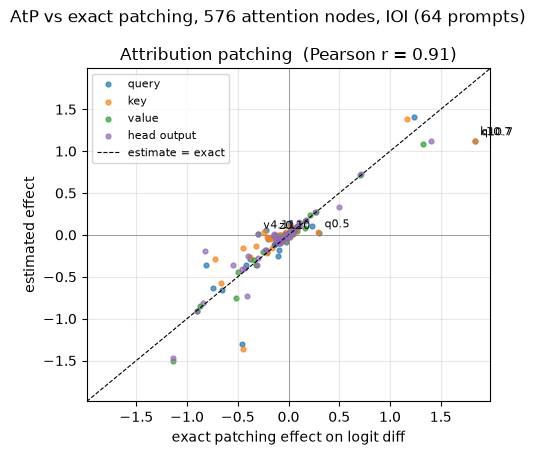

In [ ]:
grads = node_gradients(model, ioi)
atp_per_prompt = atp_estimates(clean_cache, corrupt_cache, grads)
atp = atp_per_prompt.mean(-1).cpu()

utils.plot_estimate_vs_exact(
    {"Attribution patching": atp}, exact, "AtP vs exact patching, 576 attention nodes, IOI (64 prompts)",
    highlight=["v4.11", "q10.7", "k10.7", "q0.5", "z0.10"],
)

<details><summary>Solution</summary>

```python
def atp_estimates(
    clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor], grads: dict[str, Tensor]
) -> Float[Tensor, "kind layer head batch"]:
    n_layers = len([name for name in clean_cache if name.endswith("hook_q")])
    rows = []
    for kind in KINDS:
        per_layer = []
        for layer in range(n_layers):
            name = f"blocks.{layer}.attn.hook_{kind}"
            # (batch, seq, head, d_head) -> (head, batch)
            per_layer.append(((corrupt_cache[name] - clean_cache[name]) * grads[name]).sum((1, 3)).T)
        rows.append(t.stack(per_layer))
    return t.stack(rows)
```
</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

Most points lie near the diagonal, which is why AtP's overall correlation with exact patching is high. But look at two groups of points:

- **Queries and keys of 10.7** (labelled) are *underestimated*: exact patching says about +1.8, AtP says about +1.1. They're still near the top of the ranking, so for search purposes this error is harmless.
- **Points on the horizontal line through zero**, such as `v4.11` and `z0.10`, are the dangerous ones. Exact patching says they matter (−0.30 and −0.15), AtP says they don't. These are false negatives.

Correlation is dominated by the big points that AtP gets roughly right. To see the false negatives clearly, we need a different evaluation.
</details>

## Evaluating a search method: recall versus cost

How do people actually use attribution patching? Usually as a **filter**: compute cheap scores for every node, then run exact patching (or a closer look) on the nodes with the
largest scores, in order, until you're confident you've found everything that matters. Under that workflow, the question that matters is:

> If I verify nodes in the order this method ranks them, how many do I need to verify before I've found every *important* node?

That's the evaluation Kramár et al. use. We'll call a node **important** if its exact effect has magnitude above some threshold (we'll use 0.1, about 3% of the clean logit
difference), and plot the fraction of important nodes found against the number of nodes verified. A perfect method would find them all after exactly as many verifications as there
are important nodes. A random order is the baseline every method must beat.

Notice that this metric doesn't care about the *values* of the estimates, only the ranking, and it punishes a false negative much more than a false positive: a single important
node ranked last forces you to verify everything.

### Exercise - recall curves

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `recall_curve`. Given scores and exact effects (both of the same shape; flatten them), order the nodes by **decreasing absolute score**, and return a 1D tensor whose
entry `j` is the fraction of important nodes (`|exact| > threshold`) among the first `j + 1` nodes in that order.

In [ ]:
def recall_curve(scores: Tensor, exact: Tensor, threshold: float) -> Float[Tensor, " n_nodes"]:
    raise NotImplementedError()


tests.test_recall_curve(recall_curve)

<details><summary>Solution</summary>

```python
def recall_curve(scores: Tensor, exact: Tensor, threshold: float) -> Float[Tensor, " n_nodes"]:
    scores, exact = scores.flatten().cpu(), exact.flatten().cpu()
    important = exact.abs() > threshold
    order = scores.abs().argsort(descending=True, stable=True)
    return important[order].float().cumsum(0) / important.sum()
```
</details>

And the random baseline, which we provide: recall curves for 200 random orderings, summarised by their mean and 5th/95th percentiles.

In [ ]:
def random_recall_band(exact: Tensor, threshold: float, n_orders: int = 200, seed: int = 0) -> tuple[Tensor, Tensor, Tensor]:
    generator = t.Generator().manual_seed(seed)
    curves = t.stack([recall_curve(t.rand(exact.numel(), generator=generator), exact, threshold) for _ in range(n_orders)])
    return curves.mean(0), curves.quantile(0.05, dim=0), curves.quantile(0.95, dim=0)


def nodes_for_full_recall(scores: Tensor, exact: Tensor, threshold: float) -> int:
    """How many nodes you must verify (in score order) before every important node has been found."""
    curve = recall_curve(scores, exact, threshold)
    return int((curve < 1.0).sum().item()) + 1


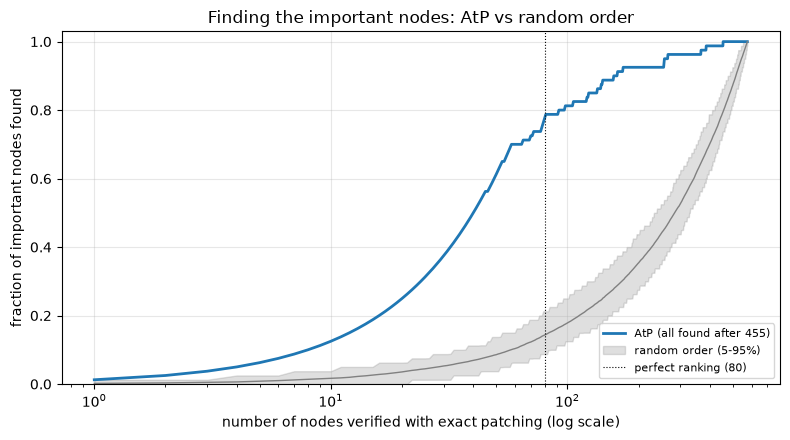

In [ ]:
THRESHOLD = 0.1
n_important = int((exact.abs() > THRESHOLD).sum())
print(f"{n_important} of 576 nodes are important (|exact effect| > {THRESHOLD})")
print(f"AtP needs {nodes_for_full_recall(atp, exact, THRESHOLD)} verifications to find all of them")

utils.plot_recall_curves(
    {"AtP": recall_curve(atp, exact, THRESHOLD)},
    n_important,
    "Finding the important nodes: AtP vs random order",
    random_band=random_recall_band(exact, THRESHOLD),
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">80 of 576 nodes are important (|exact effect| > 0.1)
AtP needs 455 verifications to find all of them</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

AtP is far better than random at the start: it finds about 80% of the important nodes in its first 80 or so verifications, where a random order would have found about 14%. But the
curve then flattens out, and the last few important nodes only turn up after **455** verifications, which is 79% of all nodes. If your verification budget had been 100 or 200
nodes, you'd have missed them.

This "long tail" is what the AtP* paper is about. A method can look excellent on correlation and on average-case recall, while its worst case, which is what determines whether your
circuit is complete, is barely better than checking everything.
</details>

### Who are the false negatives?

In [ ]:
important = (exact.flatten().abs() > THRESHOLD).nonzero().flatten()
atp_rank = atp.flatten().abs().argsort(descending=True).argsort()
worst = important[atp_rank[important].argsort(descending=True)][:8]
rows = [
    {"node": names[i], "exact effect": exact.flatten()[i].item(), "AtP estimate": atp.flatten()[i].item(), "AtP rank": atp_rank[i].item() + 1}
    for i in worst.tolist()
]
display(pd.DataFrame(rows).set_index("node").style.format({"exact effect": "{:+.3f}", "AtP estimate": "{:+.3f}"}))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">        exact effect  AtP estimate  AtP rank
node
k11.1         -0.102        -0.003       455
z0.10         -0.146        +0.005       427
z5.8          -0.132        -0.006       410
z0.1          -0.154        -0.011       336
v4.11         -0.303        +0.012       307
z4.11         -0.303        +0.012       308
q0.5          +0.300        +0.024       257
z4.7          -0.101        -0.025       238</pre>

</details>

Keep these nodes in mind. Two of them are **queries and keys** (k11.1 and q0.5), which is where AtP*'s first fix is aimed. The others are values and head outputs, where the
attention softmax can't be the problem. We'll come back to them in section 3️⃣.

## Summary of 1️⃣

- Exact patching of all 576 attention nodes is cheap on GPT-2 Small, which makes it an ideal testbed: we have ground truth for every node.
- AtP correlates well with exact patching, but its *worst-case* recall is poor: finding all 80 important nodes requires verifying 455.
- Correlation and recall measure different things. If you're using attribution to decide where to look, recall of important nodes, and especially the long tail, is what matters.

# 2️⃣ Attention Saturation and the QK Fix

> ##### Learning Objectives
>
> - Understand why first-order approximations fail when a patch moves a softmax between saturated states
> - Recompute attention patterns from queries and keys, matching TransformerLens exactly
> - Implement the QK fix and measure how much it improves query and key estimates

## Why queries and keys are hard

Patching a value vector changes what a head writes *in proportion* to how much it was attending to that position: the map from values to the head's output is linear. Patching a
query or a key is different. It changes the attention scores, which then go through a softmax:

$$
A_{s,t} = \frac{\exp(q_s \cdot k_t / \sqrt{d_{head}})}{\sum_{t'} \exp(q_s \cdot k_{t'} / \sqrt{d_{head}})}
$$

The softmax is flat almost everywhere and steep in a narrow region. If a head is attending almost entirely to one position (say $A_{s,t} = 0.99$), the gradient of $A_{s,t}$ with
respect to the score is $A_{s,t}(1 - A_{s,t}) \approx 0.01$: tiny. Patching a key so that the head attends somewhere else entirely changes $A_{s,t}$ by $-0.99$, but the first-order
approximation predicts a change of roughly $0.01 \times \Delta\text{score}$. Saturation can also go the other way, overestimating a change that the softmax damps out.

The fix proposed by Kramár et al. is simple. Computing the new attention pattern under a query or key patch is cheap: it only involves that one head's scores and a softmax, not a
forward pass through the rest of the network. So compute the pattern exactly, and only use the linear approximation for everything *after* the pattern:

$$
\hat{c}_{\text{QK fix}}(n; i) = \sum_{s,t} \left(A'_{s,t} - A_{s,t}\right) \frac{\partial M_i}{\partial A_{s,t}}
$$

where $A'$ is the pattern recomputed with the patched query (or key) and the clean key (or query). We already have $\partial M_i / \partial A$: `node_gradients` returned the
gradient with respect to `hook_pattern`.

### Exercise - recompute attention patterns from queries and keys

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `pattern_from_qk`, which takes queries and keys of shape `(batch, seq, n_heads, d_head)` and returns the attention pattern of shape `(batch, n_heads, seq_q, seq_k)`,
exactly as GPT-2 computes it: scale the scores by $1/\sqrt{d_{head}}$, apply the causal mask (a query can't attend to later keys), and softmax over keys. The test compares your
output against the model's own `hook_pattern`.

In [ ]:
def pattern_from_qk(
    q: Float[Tensor, "batch seq n_heads d_head"], k: Float[Tensor, "batch seq n_heads d_head"]
) -> Float[Tensor, "batch n_heads seq_q seq_k"]:
    raise NotImplementedError()


tests.test_pattern_from_qk(pattern_from_qk, model, ioi)

<details>
<summary>Hint</summary>

`t.einsum("bqhd,bkhd->bhqk", q, k)` gives the raw scores. For the mask, `t.triu(t.ones(seq, seq, dtype=t.bool), diagonal=1)` is true exactly where the key position is after the
query position; fill those entries with `-inf` before the softmax.
</details>


<details><summary>Solution</summary>

```python
def pattern_from_qk(
    q: Float[Tensor, "batch seq n_heads d_head"], k: Float[Tensor, "batch seq n_heads d_head"]
) -> Float[Tensor, "batch n_heads seq_q seq_k"]:
    scores = t.einsum("bqhd,bkhd->bhqk", q, k) / math.sqrt(q.shape[-1])
    seq = scores.shape[-1]
    mask = t.triu(t.ones(seq, seq, dtype=t.bool, device=scores.device), diagonal=1)
    return scores.masked_fill(mask, float("-inf")).softmax(dim=-1)
```
</details>

Before implementing the fix, let's look at saturation directly. We'll take head 10.7 (the negative name mover with the largest effect) on one prompt, patch its key vectors, and
compare three things at the final position: the clean attention pattern, the pattern after patching (computed exactly with your function), and the first-order prediction of the new
pattern, $A + J \Delta$, where $J$ is the Jacobian of the softmax at the clean scores.


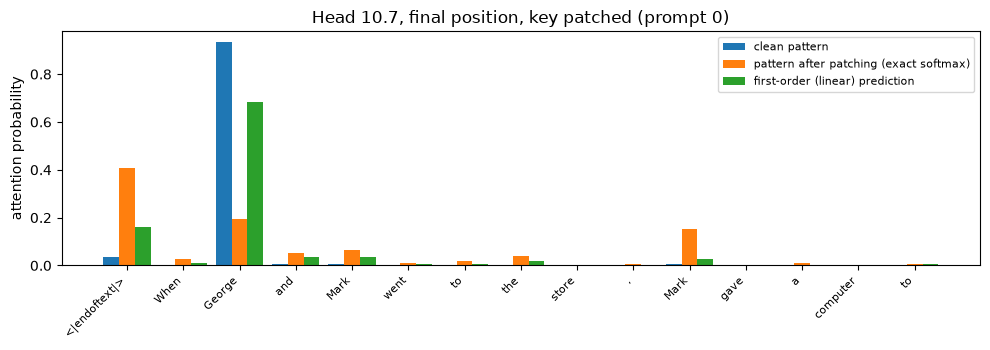

In [ ]:
layer, head, prompt = 10, 7, 0
q_clean = clean_cache[f"blocks.{layer}.attn.hook_q"][prompt : prompt + 1]
k_clean = clean_cache[f"blocks.{layer}.attn.hook_k"][prompt : prompt + 1]
k_corrupt = corrupt_cache[f"blocks.{layer}.attn.hook_k"][prompt : prompt + 1]

k_patched = k_clean.clone()
k_patched[:, :, head] = k_corrupt[:, :, head]
clean_row = pattern_from_qk(q_clean, k_clean)[0, head, -1]
patched_row = pattern_from_qk(q_clean, k_patched)[0, head, -1]

# First-order prediction: A + J @ (change in scores), with J = diag(A) - A A^T
scale = math.sqrt(model.cfg.d_head)
delta_scores = (q_clean[0, -1, head] @ (k_patched[0, :, head] - k_clean[0, :, head]).T) / scale
jacobian = t.diag(clean_row) - t.outer(clean_row, clean_row)
linear_row = clean_row + jacobian @ delta_scores

tokens = [model.to_string(tok) for tok in ioi.clean_tokens[prompt]]
utils.plot_saturation(clean_row, patched_row, linear_row, tokens, f"Head {layer}.{head}, final position, key patched (prompt {prompt})")

<details>
<summary>Help - how should I interpret this plot?</summary>

On the clean prompt, 10.7 attends from the final position mostly to the indirect object's name. After patching its keys with keys from a prompt containing different names, it no
longer recognises that name, and its attention spreads out (mostly onto the BOS token). The first-order prediction gets the *direction* of the change right but not its size, and it
can even predict negative "probabilities", which the real softmax can never produce. Everything downstream of the pattern then inherits this error.
</details>

### Exercise - the QK fix

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement `qk_fix_estimates`, which returns QK-fixed estimates for every query node and every key node, with shape `(2, n_layers, n_heads, batch)` (index 0 for queries, 1 for
keys).

For each layer, and for each head:

- **query node**: recompute the pattern using the head's corrupted queries and clean keys;
- **key node**: recompute the pattern using clean queries and the head's corrupted keys;

then take $\sum_{s,t} (A' - A) \odot \partial M / \partial A$ for that head, per prompt. You can avoid a loop over heads for the query and key nodes by noting that recomputing the
pattern with *all* heads' queries patched gives, for each head, exactly the pattern you'd get by patching only that head's query (heads don't interact inside an attention layer).

In [ ]:
def qk_fix_estimates(
    clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor], grads: dict[str, Tensor]
) -> Float[Tensor, "2 layer head batch"]:
    raise NotImplementedError()


tests.test_qk_fix_estimates(qk_fix_estimates, cache_nodes, node_gradients, model, ioi)

<details><summary>Solution</summary>

```python
def qk_fix_estimates(
    clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor], grads: dict[str, Tensor]
) -> Float[Tensor, "2 layer head batch"]:
    n_layers = len([name for name in clean_cache if name.endswith("hook_q")])
    out = []
    for which in ["q", "k"]:
        per_layer = []
        for layer in range(n_layers):
            q = clean_cache[f"blocks.{layer}.attn.hook_q"]
            k = clean_cache[f"blocks.{layer}.attn.hook_k"]
            if which == "q":
                q = corrupt_cache[f"blocks.{layer}.attn.hook_q"]
            else:
                k = corrupt_cache[f"blocks.{layer}.attn.hook_k"]
            name = f"blocks.{layer}.attn.hook_pattern"
            delta = pattern_from_qk(q, k) - clean_cache[name]
            # (batch, head, q, k) -> (head, batch)
            per_layer.append((delta * grads[name]).sum((-1, -2)).T)
        out.append(t.stack(per_layer))
    return t.stack(out)
```
</details>

<details>
<summary>Hint</summary>

For each layer, build the patched queries/keys (all heads patched at once is fine, as explained above), call `pattern_from_qk`, subtract the clean pattern from the cache, multiply
elementwise by `grads[f"blocks.{layer}.attn.hook_pattern"]`, and sum over the last two dimensions. You'll get shape `(batch, n_heads)`; transpose to `(n_heads, batch)`.
</details>

We'll combine this with the ordinary AtP estimates for values and head outputs (where there's no softmax to fix) into a single "AtP + QK fix" estimate:

In [ ]:
def atp_qk_fixed(clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor], grads: dict[str, Tensor]) -> Tensor:
    """Per-prompt AtP estimates for all nodes, with queries and keys replaced by their QK-fixed estimates."""
    estimates = atp_estimates(clean_cache, corrupt_cache, grads).clone()
    estimates[:2] = qk_fix_estimates(clean_cache, corrupt_cache, grads)
    return estimates


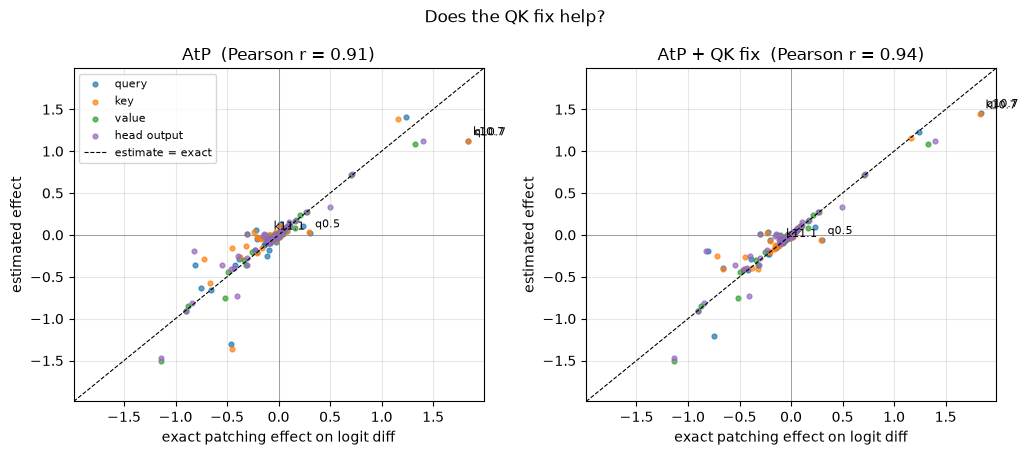

In [ ]:
qk_per_prompt = atp_qk_fixed(clean_cache, corrupt_cache, grads)
atp_qk = qk_per_prompt.mean(-1).cpu()

utils.plot_estimate_vs_exact(
    {"AtP": atp, "AtP + QK fix": atp_qk}, exact, "Does the QK fix help?", highlight=["q10.7", "k10.7", "k11.1", "q0.5"]
)
for k, kind in enumerate(KINDS):
    r_atp = t.corrcoef(t.stack([atp[k].flatten(), exact[k].flatten()]))[0, 1]
    r_fix = t.corrcoef(t.stack([atp_qk[k].flatten(), exact[k].flatten()]))[0, 1]
    print(f"{utils.KIND_LABELS[kind]:>12}: Pearson r with exact  AtP {r_atp:.3f}  ->  AtP + QK fix {r_fix:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">       query: Pearson r with exact  AtP 0.878  ->  AtP + QK fix 0.927
         key: Pearson r with exact  AtP 0.842  ->  AtP + QK fix 0.957
       value: Pearson r with exact  AtP 0.971  ->  AtP + QK fix 0.971
 head output: Pearson r with exact  AtP 0.936  ->  AtP + QK fix 0.936</pre>

</details>

The QK fix does what it says. The estimates for queries and keys move much closer to the diagonal: for 10.7's query and key, from about +1.1 to about +1.45 (exact: +1.8). The
correlation for keys goes from 0.84 to 0.96. Values and head outputs are unchanged, as they should be.

But what about recall? Let's check:

In [ ]:
print(f"Verifications needed to find all {n_important} important nodes:")
print(f"  AtP:          {nodes_for_full_recall(atp, exact, THRESHOLD)}")
print(f"  AtP + QK fix: {nodes_for_full_recall(atp_qk, exact, THRESHOLD)}")
for name in ["k11.1", "q0.5"]:
    i = names.index(name)
    print(f"  {name}: exact {exact.flatten()[i]:+.3f}, AtP {atp.flatten()[i]:+.3f}, AtP + QK fix {atp_qk.flatten()[i]:+.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Verifications needed to find all 80 important nodes:
  AtP:          455
  AtP + QK fix: 491
  k11.1: exact -0.102, AtP -0.003, AtP + QK fix -0.092
  q0.5: exact +0.300, AtP +0.024, AtP + QK fix -0.056</pre>

</details>

<details>
<summary>Help - the QK fix made recall worse?!</summary>

Yes, slightly: the worst-case number of verifications went from 455 to 491. Look at the two query/key false negatives from section 1️⃣:

- **k11.1** is fixed: the QK-fixed estimate (−0.092) is close to the exact effect (−0.102).
- **q0.5** gets *worse*: exact +0.30, AtP +0.024, QK fix −0.056. The QK fix computes the pattern change exactly, but the gradient after the pattern is still a linear approximation, and for a head in layer 0 almost the whole network is "after the pattern".

And the last important node to be found is no longer a query or key at all; it's one of the value/output false negatives, which the QK fix doesn't touch. Fixing the estimates for
the nodes you were already getting roughly right (like 10.7) doesn't help recall, which is limited by the nodes you're getting badly wrong. So the QK fix is a real improvement in
estimate quality, but on its own it doesn't solve the false-negative problem on this task.
</details>

## Summary of 2️⃣

- When a patch moves an attention softmax between saturated regions, the gradient can badly misjudge the size of the change.
- Recomputing the attention pattern exactly is cheap, and linearising only after the pattern (the QK fix) substantially improves estimates for queries and keys.
- But better estimates on average aren't the same as fewer false negatives. On IOI, the QK fix doesn't improve worst-case recall, because the remaining false negatives are mostly values and head outputs.

# 3️⃣ Cancellation and GradDrop

> ##### Learning Objectives
>
> - Understand how gradients through different paths can cancel even when effects don't
> - Implement GradDrop by detaching one layer's contribution on the backward pass
> - Run a component-wise ablation of AtP* rather than taking the recipe on trust
> - Explain AtP's false negatives on IOI in terms of per-prompt effects

## How gradients can cancel

A component's activation reaches the output through many paths: directly through the residual stream, and indirectly through every later attention head and MLP that reads it. The
gradient at the clean input is the *sum* over all these paths. If one path contributes $+1$ and another contributes $-1$, the gradient is zero, and AtP says the component doesn't
matter.

That would be fine if the actual effects also cancelled. But the paths aren't equally linear. Suppose the indirect path goes through a ReLU that's switched on at the clean input,
and the patch switches it off. Then the true effect is the direct path's effect alone, while AtP sees the two paths' clean-input gradients cancel and reports zero.

Kramár et al. call this **cancellation** and propose **GradDrop**. For each layer $\ell$, recompute the gradient with layer $\ell$'s outputs detached from the backward pass (the
forward pass is unchanged, so the Taylor expansion is still taken at the clean input). This removes every path that goes *through* layer $\ell$. Compute the AtP estimate with each
of these modified gradients, take absolute values, and average:

$$
\hat{c}_{\text{GD}}(n) = \mathbb{E}_i\left[\frac{1}{L - 1} \sum_{\ell = 1}^{L} \left|\hat{c}_{\text{AtP}, \ell\text{ dropped}}(n; i)\right|\right]
$$

The idea is that two cancelling paths almost always go through different layers, so dropping one of those layers reveals the other path's contribution. The sum is divided by $L -
1$ because dropping a node's *own* layer always gives zero for that node (all of its effect flows through its own layer's output).

**AtP\*** is the combination of the QK fix and GradDrop.

Note what GradDrop gives up: its scores are absolute values, so they no longer estimate the *signed* effect, and they can overestimate the magnitude. That's the right trade for a
search method, where a false negative is much more costly than a false positive.

## A toy model where AtP returns exactly zero

Before running GradDrop on GPT-2, let's build the smallest possible example of cancellation, where we can work everything out by hand. The model has a one-dimensional residual
stream and two layers:

$$
\begin{aligned}
r_0 &= x \\
n &= 2x & \text{(layer 0's output; this is the node we'll patch)} \\
r_1 &= r_0 + n \\
m &= -\text{ReLU}(r_1 - 2) & \text{(layer 1's output)} \\
y &= r_1 + m
\end{aligned}
$$

On the clean input $x = 1$: $n = 2$, $r_1 = 3$, $m = -1$, so $y = 2$. Now patch the node with its value on the corrupted input $x' = 0$, i.e. set $n = 0$ (keeping $r_0 = 1$): then
$r_1 = 1$, the ReLU switches off, $m = 0$, and $y = 1$. The exact effect is $-1$.

What does AtP say? At the clean input, $\partial y / \partial n = 1$ (directly, through $r_1$ into $y$) $- 1$ (through the ReLU, which is on) $= 0$. So AtP's estimate is $\Delta n
\times 0 = 0$.

With GradDrop: dropping layer 1 removes the path through the ReLU, so the gradient becomes $1$ and the estimate is $\Delta n \times 1 = -2$. Dropping layer 0 (the node's own layer)
gives $0$. With $L = 2$ layers, the GradDrop score is $(|-2| + 0) / (2 - 1) = 2$.

### Exercise - implement the toy and its three estimates

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `toy_forward`, which computes $y$ from $x$, optionally replacing the node $n$ with `node_override`, and optionally detaching layer `drop_layer`'s output (0 for $n$, 1 for
$m$) on the backward pass. Then implement `toy_estimates`, which returns a dict with the exact effect, the AtP estimate, and the GradDrop score for patching the node from `x_clean`
to `x_corrupt`. Use autograd for the gradients (don't hard-code them).

In [ ]:
def toy_forward(x: Tensor, node_override: Tensor | None = None, drop_layer: int | None = None) -> Tensor:
    """The two-layer cancellation toy. Returns y."""
    raise NotImplementedError()


def toy_estimates(x_clean: Tensor, x_corrupt: Tensor) -> dict[str, float]:
    raise NotImplementedError()


tests.test_toy(toy_forward, toy_estimates)
print({key: value + 0.0 for key, value in toy_estimates(t.tensor(1.0), t.tensor(0.0)).items()})  # + 0.0 turns -0.0 into 0.0

<details><summary>Solution</summary>

```python
def toy_forward(x: Tensor, node_override: Tensor | None = None, drop_layer: int | None = None) -> Tensor:
    """The two-layer cancellation toy. Returns y."""
    r0 = x
    n = 2 * x if node_override is None else node_override
    r1 = r0 + (n.detach() if drop_layer == 0 else n)
    m = -t.relu(r1 - 2)
    return r1 + (m.detach() if drop_layer == 1 else m)


def toy_estimates(x_clean: Tensor, x_corrupt: Tensor) -> dict[str, float]:
    n_clean, n_corrupt = 2 * x_clean, 2 * x_corrupt
    exact = (toy_forward(x_clean, node_override=n_corrupt) - toy_forward(x_clean)).item()

    def atp_with(drop_layer: int | None) -> float:
        n = n_clean.clone().requires_grad_(True)
        y = toy_forward(x_clean, node_override=n, drop_layer=drop_layer)
        if not y.requires_grad:  # dropping the node's own layer cuts every path from n to y
            return 0.0
        (grad,) = t.autograd.grad(y, n)
        return ((n_corrupt - n_clean) * grad).item()

    n_layers = 2
    graddrop = sum(abs(atp_with(layer)) for layer in range(n_layers)) / (n_layers - 1)
    return {"exact": exact, "atp": atp_with(None), "graddrop": graddrop}
```
</details>

<details>
<summary>Hint</summary>

For AtP, make a leaf tensor `n = (2 * x_clean).requires_grad_(True)`, pass it as `node_override`, and get the gradient with `t.autograd.grad(y, n)`. For GradDrop, do the same with
`drop_layer=0` and `drop_layer=1`.

With `drop_layer=0` the node's own output is detached, so `y` doesn't depend on `n` at all and has no `grad_fn`: calling backward on it raises an error. That case is exactly the
"dropping a node's own layer gives zero" case from the formula, so return `0.0` when `y.requires_grad` is `False`.
</details>

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">All tests in `test_toy` passed!
{'exact': -1.0, 'atp': 0.0, 'graddrop': 2.0}</pre>

</details>

AtP misses the node entirely; GradDrop flags it, with a magnitude that's the right order but not the right value (2 instead of 1). For finding important nodes, that's exactly what
we want.

## AtP* on GPT-2

Now let's run the real thing. If you haven't yet implemented the `drop_layer` argument of `node_gradients`, do it now (see the instructions in section 1️⃣), and re-run the test.

In [ ]:
tests.test_node_gradients(node_gradients, model, ioi, check_drop=True)

### Exercise - AtP* scores

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `graddrop_scores`, which returns the AtP* score for every node, with shape `(4, n_layers, n_heads)`. For each layer $\ell$, compute gradients with that layer dropped,
compute the QK-fixed per-prompt estimates (`atp_qk_fixed`), and add their absolute values to a running total. Divide by $L - 1$ and average over prompts.

This needs $L = 12$ backward passes, which is still very cheap compared to 576 forward passes.

In [ ]:
def graddrop_scores(
    model: HookedTransformer, task: Task, clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor]
) -> Float[Tensor, "kind layer head"]:
    raise NotImplementedError()


tests.test_graddrop_scores(graddrop_scores, cache_nodes, model, ioi)


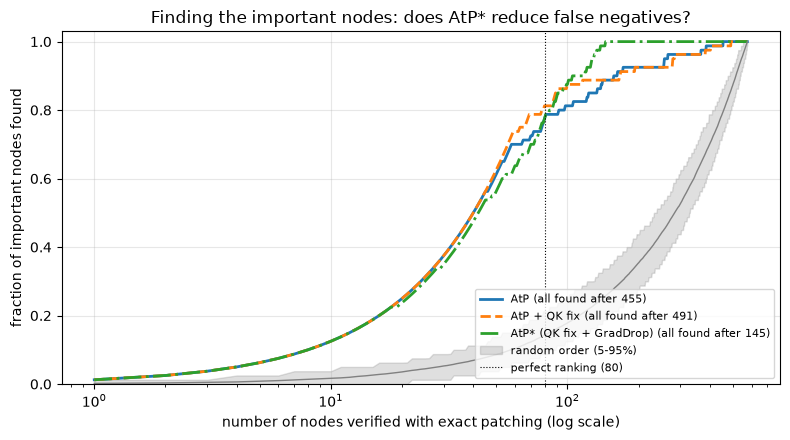

In [ ]:
t0 = time.time()
atp_star = graddrop_scores(model, ioi, clean_cache, corrupt_cache).cpu()
print(f"AtP* scores for 576 nodes took {time.time() - t0:.2f}s")

utils.plot_recall_curves(
    {
        "AtP": recall_curve(atp, exact, THRESHOLD),
        "AtP + QK fix": recall_curve(atp_qk, exact, THRESHOLD),
        "AtP* (QK fix + GradDrop)": recall_curve(atp_star, exact, THRESHOLD),
    },
    n_important,
    "Finding the important nodes: does AtP* reduce false negatives?",
    random_band=random_recall_band(exact, THRESHOLD),
)

<details><summary>Solution</summary>

```python
def graddrop_scores(
    model: HookedTransformer, task: Task, clean_cache: dict[str, Tensor], corrupt_cache: dict[str, Tensor]
) -> Float[Tensor, "kind layer head"]:
    n_layers = model.cfg.n_layers
    total = None
    for drop_layer in range(n_layers):
        grads = node_gradients(model, task, drop_layer=drop_layer)
        estimates = atp_qk_fixed(clean_cache, corrupt_cache, grads).abs()
        total = estimates if total is None else total + estimates
    return (total / (n_layers - 1)).mean(-1)
```
</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

AtP* is slightly *worse* than AtP at the very start of the curve (its absolute-value scores promote some nodes whose effects are large on individual prompts but small on average,
so a few unimportant nodes get verified early). But its long tail is much shorter: it finds every important node after verifying about 145 nodes, against 455 for AtP and 491 for
AtP with the QK fix. That's the paper's headline result, reproduced: AtP* trades a little early precision for a large reduction in false negatives.
</details>

## Which ingredient is doing the work?

AtP* combines three changes relative to AtP: the QK fix, gradient dropping, and an aggregation that averages the *absolute value* of per-prompt estimates instead of taking the
absolute value of the average. The paper motivates the second one; the third comes along with it, because GradDrop's scores are defined as sums of absolute values. It's worth
asking which of them is responsible for the improvement, rather than taking the recipe on trust. Let's compare five variants on the number of verifications needed for full recall,
at three importance thresholds.


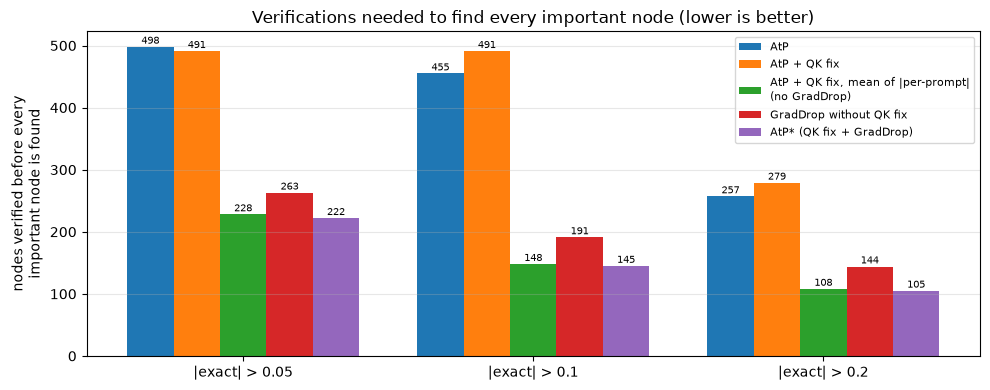

In [ ]:
# GradDrop without the QK fix, for the ablation
total = None
for drop_layer in range(model.cfg.n_layers):
    estimates = atp_estimates(clean_cache, corrupt_cache, node_gradients(model, ioi, drop_layer=drop_layer)).abs()
    total = estimates if total is None else total + estimates
graddrop_no_qk = (total / (model.cfg.n_layers - 1)).mean(-1).cpu()

variants = {
    "AtP": atp.abs(),
    "AtP + QK fix": atp_qk.abs(),
    "AtP + QK fix, mean of |per-prompt|\n(no GradDrop)": qk_per_prompt.abs().mean(-1).cpu(),
    "GradDrop without QK fix": graddrop_no_qk,
    "AtP* (QK fix + GradDrop)": atp_star,
}
thresholds = [0.05, 0.1, 0.2]
table = {name: {th: nodes_for_full_recall(scores, exact, th) for th in thresholds} for name, scores in variants.items()}
display(pd.DataFrame(table).T.rename(columns=lambda th: f"|exact| > {th} ({int((exact.abs() > th).sum())} nodes)"))
utils.plot_ingredients(table, "Verifications needed to find every important node (lower is better)")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                                  |exact| > 0.05 (113 nodes)  |exact| > 0.1 (80 nodes)  |exact| > 0.2 (57 nodes)
AtP                                                                      498                       455                       257
AtP + QK fix                                                             491                       491                       279
AtP + QK fix, mean of |per-prompt|\n(no GradDrop)                        228                       148                       108
GradDrop without QK fix                                                  263                       191                       144
AtP* (QK fix + GradDrop)                                                 222                       145                       105</pre>

</details>

<details>
<summary>Help - how should I interpret this table?</summary>

The third row is the surprise. Simply averaging the absolute values of the per-prompt QK-fixed estimates, **without dropping any gradients**, gets almost all of AtP*'s improvement:
148 verifications versus 145 for full AtP* at the 0.1 threshold, and similarly at the other thresholds. GradDrop without the QK fix is worse than both.

So on IOI in GPT-2 Small, gradient dropping itself contributes very little. The ingredient that matters is the change in aggregation, from "absolute value of the average estimate"
to "average of the absolute per-prompt estimates". This doesn't contradict the paper: GradDrop really does fix cancellation, as the toy shows, and Kramár et al. report it helping
on larger models and other tasks. It does show that the false negatives we found in section 1️⃣ are mostly *not* caused by cancellation between paths. The next exercise finds out
what they are caused by.
</details>

### Exercise - look at the false negatives prompt by prompt

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

We have per-prompt exact effects (`exact_per_prompt`, from section 1️⃣) and per-prompt AtP estimates (`atp_per_prompt`). For the node `v4.11`, plot one against the other (use
`utils.plot_per_prompt`), and compute the correlation between them, the fraction of prompts where the exact effect is negative, and the means. Then do the same for `z0.10` and
`k11.1`.

Before you run it, make a prediction. AtP says $+0.01$ on average and exact patching says $-0.30$. Which of these do you expect?

- (a) AtP's per-prompt estimates are noise, uncorrelated with the exact effects.
- (b) AtP's per-prompt estimates track the exact effects, but are shifted by a constant.
- (c) The exact effects have a consistent sign, and AtP gets the sign wrong on every prompt.


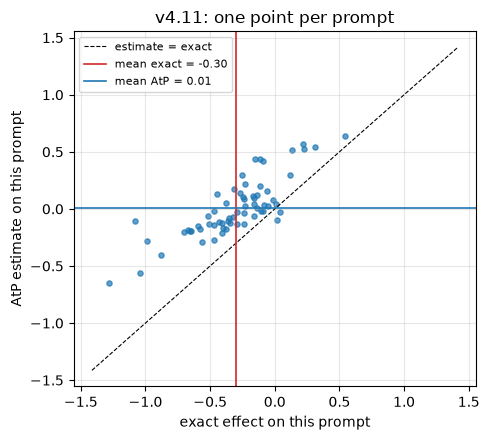

In [ ]:
# YOUR CODE HERE - compare per-prompt exact effects and AtP estimates for v4.11, z0.10 and k11.1

<details><summary>Solution</summary>

```python
for name in ["v4.11", "z0.10", "k11.1"]:
    k, rest = KINDS.index(name[0]), name[1:]
    layer, head = map(int, rest.split("."))
    per_exact = exact_per_prompt[k, layer, head]
    per_atp = atp_per_prompt[k, layer, head]
    r = t.corrcoef(t.stack([per_exact, per_atp]))[0, 1].item()
    print(
        f"{name}: corr = {r:.2f}, exact < 0 on {(per_exact < 0).float().mean():.0%} of prompts, "
        f"mean exact = {per_exact.mean():+.3f}, mean AtP = {per_atp.mean():+.3f}, mean |AtP| = {per_atp.abs().mean():.3f}"
    )
    if name == "v4.11":
        utils.plot_per_prompt(per_exact, per_atp, name)
```
</details>

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">v4.11: corr = 0.82, exact < 0 on 86% of prompts, mean exact = -0.303, mean AtP = +0.012, mean |AtP| = 0.192
z0.10: corr = 0.86, exact < 0 on 72% of prompts, mean exact = -0.146, mean AtP = +0.005, mean |AtP| = 0.229
k11.1: corr = 0.92, exact < 0 on 62% of prompts, mean exact = -0.102, mean AtP = -0.003, mean |AtP| = 0.323</pre>

</details>

<details>
<summary>Answer and discussion</summary>

The answer is **(b)**. Per prompt, AtP is a good estimate of *how much this prompt differs from the others*: the correlations are 0.82 to 0.92. But its estimates are shifted
relative to the truth by a roughly constant offset (for v4.11, about +0.3), so they're centred on zero while the exact effects are centred on −0.3. The effect of 4.11 has a part
that varies from prompt to prompt (which AtP captures) and a consistent part (which AtP misses, presumably because of a nonlinearity somewhere downstream that the first-order
approximation can't see).

This explains the ablation. Taking the absolute value *before* averaging means a node whose per-prompt estimates swing between, say, −0.3 and +0.3 gets a score of about 0.2 rather
than 0. It's a cheap way to say "this node matters on individual prompts, even if I can't estimate its average effect", which is exactly the right instinct for a search method.
GradDrop's definition happens to include it.

The general lesson: when you use a recipe from a paper, ablate it on your own task. The mechanism that helps may not be the one you were told about.
</details>

## Try it yourself - change the corruption

All our conclusions so far are for one corruption. [8.2] showed that the gentler `"s2"` corruption (replace only the second occurrence of the subject's name) changes which circuit
edges look important. Below, we rebuild everything for the `"s2"` corruption and rerun the comparison. Before running it, predict: will the per-prompt absolute-value aggregation
still be doing most of the work?

You can also try changing `THRESHOLD`, or the number of prompts (with fewer prompts, per-prompt effects matter more).

In [ ]:
CORRUPTION = "s2"

play = make_ioi_task(model, 64, seed=0, corruption=CORRUPTION)
play = Task(play.clean_tokens.to(device), play.corrupt_tokens.to(device), play.answers.to(device), play.metric)
play_clean, play_corrupt = cache_nodes(model, play.clean_tokens), cache_nodes(model, play.corrupt_tokens)
play_exact = exact_node_effects(model, play, play_clean, play_corrupt).cpu()
play_grads = node_gradients(model, play)
play_atp = atp_estimates(play_clean, play_corrupt, play_grads).mean(-1).cpu()
play_qk_pp = atp_qk_fixed(play_clean, play_corrupt, play_grads)
play_star = graddrop_scores(model, play, play_clean, play_corrupt).cpu()

print(f"Corruption '{CORRUPTION}': {int((play_exact.abs() > THRESHOLD).sum())} important nodes")
for name, scores in {
    "AtP": play_atp,
    "AtP + QK fix": play_qk_pp.mean(-1).cpu(),
    "mean |per-prompt| (no GradDrop)": play_qk_pp.abs().mean(-1).cpu(),
    "AtP*": play_star,
}.items():
    print(f"  {name:<32} verifications for full recall: {nodes_for_full_recall(scores, play_exact, THRESHOLD)}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Corruption 's2': 66 important nodes
  AtP                              verifications for full recall: 333
  AtP + QK fix                     verifications for full recall: 351
  mean |per-prompt| (no GradDrop)  verifications for full recall: 88
  AtP*                             verifications for full recall: 87</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The same pattern as with the ABC corruption. The QK fix on its own doesn't shorten the tail (351 versus 333 verifications), AtP* shortens it a lot (87), and averaging the absolute
per-prompt estimates without any gradient dropping gets essentially all of that gain (88). So the ablation result isn't specific to one corruption of IOI.

It is still specific to IOI in GPT-2 Small, though. If you want to find a setting where GradDrop earns its keep, see the bonus section.
</details>

## Summary of 3️⃣

- Gradients through different paths can cancel even when the paths' actual effects don't, making AtP return exactly zero for a component that matters. GradDrop fixes this by removing one layer's paths at a time.
- AtP* (QK fix + GradDrop) dramatically shortens the long tail on IOI: every important node is found after about 145 verifications instead of 455.
- But an ablation shows that on this task, almost all of the improvement comes from averaging absolute per-prompt estimates, not from gradient dropping. AtP's false negatives here are nodes whose per-prompt estimates track the true variation but miss a consistent offset.

# 4️⃣ AtP at Scale: Neurons and Verification

> ##### Learning Objectives
>
> - Apply attribution patching to MLP neurons, where exact patching is expensive
> - Design a verified search: rank cheaply, then spend a fixed budget of exact patches
> - Use group tests and adaptive bisection to find what you might have missed, and understand when they can be fooled
> - Diagnose a neuron-level false negative, and connect it to the attention-node false negatives

## Why AtP exists

On 576 attention nodes, exact patching takes ten seconds, so there's little reason to approximate. The point of attribution patching is scale. GPT-2 Small has 12 × 3072 = 36,864
MLP neurons; patching each one exactly is 36,864 forward passes (about ten minutes here, and hours or days for a model a hundred times larger). AtP scores all of them with two
forward passes and one backward pass.

So for neurons, the realistic workflow is: score everything with AtP (or AtP*), verify a **budget** of the top-ranked neurons with exact patching, and then ask how confident you
can be that nothing important is hiding in the unverified remainder.

### Exercise - AtP for every MLP neuron

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `neuron_atp`, which returns the AtP estimate (averaged over prompts) for every neuron in every MLP layer, with shape `(n_layers, d_mlp)`. A neuron's activation is its
value at `blocks.{layer}.mlp.hook_post` (after the nonlinearity), at all positions. You'll need the corrupted activations (one forward pass on the corrupted prompts) and the
gradient of the summed metric with respect to the clean activations (one forward and backward pass on the clean prompts). For each neuron, sum (corrupt − clean) × gradient over
positions, then average over prompts.

As with the attention nodes, we'll also want the per-prompt estimates later: if `per_prompt` is true, skip the average and return shape `(n_layers, d_mlp, batch)`.

In [ ]:
def neuron_atp(model: HookedTransformer, task: Task, per_prompt: bool = False) -> Tensor:
    """
    AtP estimate for every MLP neuron: shape (n_layers, d_mlp) averaged over prompts, or (n_layers, d_mlp, batch)
    if per_prompt is True.
    """
    raise NotImplementedError()


tests.test_neuron_atp(neuron_atp, model, ioi)

<details><summary>Solution</summary>

```python
def neuron_atp(model: HookedTransformer, task: Task, per_prompt: bool = False) -> Tensor:
    """
    AtP estimate for every MLP neuron: shape (n_layers, d_mlp) averaged over prompts, or (n_layers, d_mlp, batch)
    if per_prompt is True.
    """
    names = [f"blocks.{layer}.mlp.hook_post" for layer in range(model.cfg.n_layers)]
    with t.no_grad():
        _, corrupt = model.run_with_cache(task.corrupt_tokens, names_filter=lambda name: name in names)
    store = {}

    def keep(act: Tensor, hook) -> Tensor:
        act.requires_grad_(True)
        act.retain_grad()
        store[hook.name] = act
        return act

    with t.enable_grad():
        metric = task.metric(model.run_with_hooks(task.clean_tokens, fwd_hooks=[(lambda n: n in names, keep)]), task.answers)
        metric.sum().backward()
    estimates = t.stack([((corrupt[name] - store[name].detach()) * store[name].grad).sum(1).T for name in names])
    return estimates if per_prompt else estimates.mean(-1)
```
</details>

### Exercise - exact patching for selected neurons, and for groups of neurons

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `group_effects`, which takes a list of groups (each group a list of `(layer, neuron)` pairs), patches *all* neurons in a group at once with their corrupted values, and
returns the average change in metric for each group. Then implement `exact_neuron_effects` in terms of it (each neuron is a group of one).

Cache the corrupted `hook_post` activations once at the start, rather than recomputing them for every group.

In [ ]:
@t.no_grad()
def group_effects(model: HookedTransformer, task: Task, groups: list[list[tuple[int, int]]]) -> Float[Tensor, " n_groups"]:
    raise NotImplementedError()


def exact_neuron_effects(model: HookedTransformer, task: Task, neurons: list[tuple[int, int]]) -> Float[Tensor, " n_neurons"]:
    raise NotImplementedError()


tests.test_group_effects(group_effects, exact_neuron_effects, model, ioi)
tests.test_exact_neuron_effects(exact_neuron_effects, model, ioi)

<details><summary>Solution</summary>

```python
@t.no_grad()
def group_effects(model: HookedTransformer, task: Task, groups: list[list[tuple[int, int]]]) -> Float[Tensor, " n_groups"]:
    names = [f"blocks.{layer}.mlp.hook_post" for layer in range(model.cfg.n_layers)]
    _, corrupt = model.run_with_cache(task.corrupt_tokens, names_filter=lambda name: name in names)
    clean = task.metric(model(task.clean_tokens), task.answers)
    effects = []
    for group in groups:
        by_layer: dict[int, list[int]] = {}
        for layer, idx in group:
            by_layer.setdefault(layer, []).append(idx)
        hooks = []
        for layer, idxs in by_layer.items():
            name = f"blocks.{layer}.mlp.hook_post"

            def patch(act: Tensor, hook, idxs=idxs, name=name) -> Tensor:
                act[:, :, idxs] = corrupt[name][:, :, idxs]
                return act

            hooks.append((name, patch))
        patched = task.metric(model.run_with_hooks(task.clean_tokens, fwd_hooks=hooks), task.answers)
        effects.append((patched - clean).mean())
    return t.stack(effects)


def exact_neuron_effects(model: HookedTransformer, task: Task, neurons: list[tuple[int, int]]) -> Float[Tensor, " n_neurons"]:
    return group_effects(model, task, [[neuron] for neuron in neurons])
```
</details>

Now the experiment. We score all neurons with AtP, verify the top 100 with exact patching, and, as a control, also patch 300 neurons chosen uniformly at random. If AtP's ranking is
useful, the top 100 should contain neurons with much larger effects than the random sample, and AtP's estimates should agree with the exact effects on both groups.


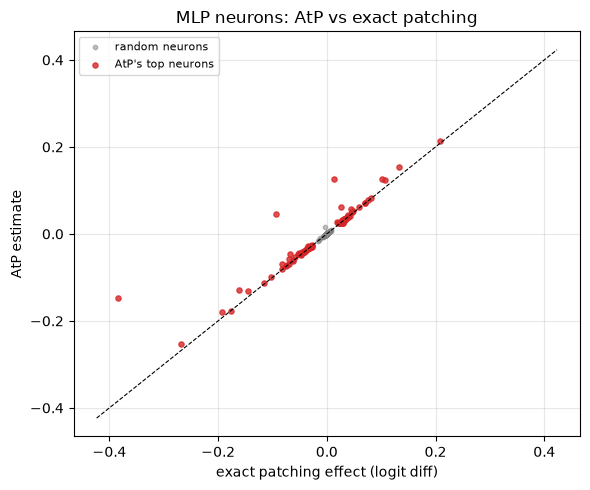

In [ ]:
t0 = time.time()
n_atp = neuron_atp(model, ioi).cpu()
print(f"AtP for all {n_atp.numel():,} neurons took {time.time() - t0:.2f}s")

d_mlp = model.cfg.d_mlp
BUDGET = 100
top_flat = n_atp.flatten().abs().argsort(descending=True)[:BUDGET]
generator = t.Generator().manual_seed(0)
random_flat = t.randperm(n_atp.numel(), generator=generator)[:300]
selected = [(i // d_mlp, i % d_mlp) for i in t.cat([top_flat, random_flat]).tolist()]

t0 = time.time()
neuron_exact = exact_neuron_effects(model, ioi, selected).cpu()
print(f"Exact patching of {len(selected)} neurons took {time.time() - t0:.1f}s")

is_top = t.zeros(len(selected), dtype=t.bool)
is_top[:BUDGET] = True
sel_atp = n_atp.flatten()[t.cat([top_flat, random_flat])]
utils.plot_neurons(sel_atp, neuron_exact, is_top, "MLP neurons: AtP vs exact patching")
print(f"Mean |exact effect|: AtP's top {BUDGET}: {neuron_exact[is_top].abs().mean():.4f}, random: {neuron_exact[~is_top].abs().mean():.4f}")
print(f"Pearson r (AtP vs exact): top {BUDGET}: {t.corrcoef(t.stack([sel_atp[is_top], neuron_exact[is_top]]))[0, 1]:.3f}, random: {t.corrcoef(t.stack([sel_atp[~is_top], neuron_exact[~is_top]]))[0, 1]:.3f}")
print(f"Largest |exact effect| among the random neurons: {neuron_exact[~is_top].abs().max():.4f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">AtP for all 36,864 neurons took 0.05s
Exact patching of 400 neurons took 6.6s
Mean |exact effect|: AtP's top 100: 0.0574, random: 0.0013
Pearson r (AtP vs exact): top 100: 0.924, random: 0.960
Largest |exact effect| among the random neurons: 0.0613</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The ranking is useful. AtP's top 100 neurons have a mean absolute effect of 0.057, about 44 times that of the random neurons (0.0013). The random neurons all sit in a tight cluster
at the origin: most neurons do almost nothing on this task, which is what you'd expect when 36,864 neurons share an effect of a few logits.

On its top 100, AtP is also a decent estimator (r = 0.92), with a few visible misses. The neuron at the far left has an exact effect of about −0.38 but an estimate of about −0.15;
one neuron with an exact effect near −0.09 gets a *positive* estimate; another with almost no effect is estimated at +0.12.

The plot can't show us the neurons that matter most for recall: important neurons that AtP ranked *low*. The random sample is our only window onto those, and 300 neurons out of
36,764 is a small window (the largest random effect is 0.06). That's what the next subsection is for.
</details>

## Checking the remainder with group tests

We've verified 100 of 36,864 neurons. Could an important neuron be hiding among the other 36,764? We can't patch them all individually (that's the whole problem), but we can patch
them in **groups**. If we patch a random group of 1,000 unverified neurons together and the metric barely moves, then (if effects add up, at least approximately) no single neuron
in that group can have had a large effect, unless its effect was cancelled by others in the same group.

That caveat is important: group tests can be fooled by cancellation between neurons in the same group, and by non-additive effects (remember how non-additive edge effects were in
[8.2]). Kramár et al. develop a more careful version of this idea, with random subsets and a statistical bound; here we'll do the simple version and look at what it tells us.


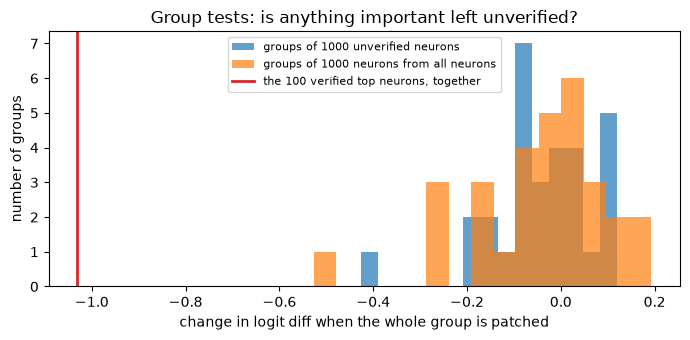

In [ ]:
verified = set(top_flat.tolist())
remainder = t.tensor([i for i in range(n_atp.numel()) if i not in verified])
GROUP_SIZE, N_GROUPS = 1000, 30
generator = t.Generator().manual_seed(1)
groups = []
for _ in range(N_GROUPS):
    members = remainder[t.randperm(len(remainder), generator=generator)[:GROUP_SIZE]]
    groups.append([(i // d_mlp, i % d_mlp) for i in members.tolist()])
remainder_effects = group_effects(model, ioi, groups).cpu()

# For comparison: groups of the same size drawn from all neurons, including the verified top 100
all_groups = []
for _ in range(N_GROUPS):
    members = t.randperm(n_atp.numel(), generator=generator)[:GROUP_SIZE]
    all_groups.append([(i // d_mlp, i % d_mlp) for i in members.tolist()])
all_effects = group_effects(model, ioi, all_groups).cpu()

top_group = group_effects(model, ioi, [[(i // d_mlp, i % d_mlp) for i in top_flat.tolist()]]).cpu()
print(f"Patching all {BUDGET} verified top neurons together: {top_group.item():+.3f}")
print(f"Groups of {GROUP_SIZE} unverified neurons: mean {remainder_effects.mean():+.3f}, most extreme {remainder_effects[remainder_effects.abs().argmax()]:+.3f}")
print(f"Groups of {GROUP_SIZE} neurons from all neurons: mean {all_effects.mean():+.3f}, most extreme {all_effects[all_effects.abs().argmax()]:+.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(remainder_effects.numpy(), bins=15, alpha=0.7, label=f"groups of {GROUP_SIZE} unverified neurons")
ax.hist(all_effects.numpy(), bins=15, alpha=0.7, label=f"groups of {GROUP_SIZE} neurons from all neurons")
ax.axvline(top_group.item(), color="tab:red", lw=2, label=f"the {BUDGET} verified top neurons, together")
ax.set_xlabel("change in logit diff when the whole group is patched")
ax.set_ylabel("number of groups")
ax.set_title("Group tests: is anything important left unverified?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Patching all 100 verified top neurons together: -1.031
Groups of 1000 unverified neurons: mean -0.040, most extreme -0.426
Groups of 1000 neurons from all neurons: mean -0.043, most extreme -0.526</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Patching the 100 verified neurons together takes about a third off the clean logit difference of 2.93, so they matter, but MLP neurons are far from the whole story on IOI (the
attention heads do most of the work).

Most groups of 1,000 unverified neurons have small effects, within about ±0.2, and their mean is slightly negative (−0.04). That's what lots of tiny effects adding up looks like.
But **one group stands out at −0.43**, larger than every single verified neuron except one. Either many small effects happen to add up in that group, or there's an important neuron
in it that AtP ranked outside its top 100. The group test can't tell these apart; it only tells you where to look.

Also notice that the groups drawn from *all* neurons (which contain about 2.7 verified neurons each, on average) don't look clearly different from the groups of unverified neurons.
At this group size, the diffuse small effects make the spread of group effects wide, so the test is not very sensitive. That's a real limitation of naive group testing, and it's
one reason the paper's version is more careful.
</details>

## Looking inside the outlier: adaptive group testing

One group of 1,000 neurons has an effect of −0.43. If a single neuron is responsible, we can find it without patching all 1,000 individually: split the group in half, patch each
half, and recurse into any half whose effect is still large. If one neuron is responsible, this takes about $2 \log_2 1000 \approx 20$ group patches instead of 1,000. This is
**adaptive group testing**, the same idea that's used to find a few defective items among many with few tests (pooled testing for infections is the best-known example).

It relies on the same assumption as the group test itself: that effects roughly add up. If a group contains one neuron with effect $+0.3$ and another with $-0.3$, the group looks
harmless and bisection never looks inside it.

### Exercise - implement `bisect_group`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `bisect_group`. It takes a group of neurons, a function `effect_fn` that returns the (scalar) effect of patching a group, and a threshold. Measure the group's effect; if
its absolute value is below the threshold, stop. Otherwise, if the group is a single neuron, report it, and if not, split it into two halves and recurse into both. Return the list
of `(neuron, effect)` pairs found, and the total number of times `effect_fn` was called.

Taking `effect_fn` as an argument (rather than calling `group_effects` directly) keeps the search logic separate from the model, which is what lets the test check it on a synthetic
problem with known answers.

In [ ]:
def bisect_group(
    group: list[tuple[int, int]], effect_fn: Callable[[list[tuple[int, int]]], float], threshold: float
) -> tuple[list[tuple[tuple[int, int], float]], int]:
    """
    Recursively halves `group`, descending only into halves with |effect| >= threshold, down to single neurons.
    Returns (found, n_calls): the single neurons with |effect| >= threshold together with their effects, and the
    number of calls made to effect_fn.
    """
    raise NotImplementedError()


tests.test_bisect_group(bisect_group)

<details>
<summary>Hint</summary>

A recursive inner function is the simplest way to write this. Use a `nonlocal` counter (or a one-element list) to count the calls to `effect_fn`.
</details>


<details><summary>Solution</summary>

```python
def bisect_group(
    group: list[tuple[int, int]], effect_fn: Callable[[list[tuple[int, int]]], float], threshold: float
) -> tuple[list[tuple[tuple[int, int], float]], int]:
    """
    Recursively halves `group`, descending only into halves with |effect| >= threshold, down to single neurons.
    Returns (found, n_calls): the single neurons with |effect| >= threshold together with their effects, and the
    number of calls made to effect_fn.
    """
    n_calls = 0

    def recurse(subgroup: list[tuple[int, int]]) -> list[tuple[tuple[int, int], float]]:
        nonlocal n_calls
        n_calls += 1
        effect = effect_fn(subgroup)
        if abs(effect) < threshold:
            return []
        if len(subgroup) == 1:
            return [(subgroup[0], effect)]
        mid = len(subgroup) // 2
        return recurse(subgroup[:mid]) + recurse(subgroup[mid:])

    found = recurse(group)
    return found, n_calls
```
</details>

Now let's bisect the outlier group. Each call to `effect_fn` is one `group_effects` call, which costs a few forward passes.

In [ ]:
worst = int(remainder_effects.abs().argmax())
found, n_calls = bisect_group(groups[worst], lambda group: group_effects(model, ioi, [group]).item(), threshold=0.1)

print(f"Group {worst} (effect {remainder_effects[worst]:+.3f}): bisection used {n_calls} group patches")
abs_atp = n_atp.abs()
for (layer, idx), effect in found:
    rank = int((abs_atp > abs_atp[layer, idx]).sum()) + 1
    print(f"  L{layer}N{idx}: exact effect {effect:+.3f}, AtP estimate {n_atp[layer, idx]:+.4f} (AtP rank {rank:,} of {n_atp.numel():,})")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Group 5 (effect -0.426): bisection used 21 group patches
  L1N79: exact effect -0.322, AtP estimate -0.0056 (AtP rank 1,222 of 36,864)</pre>

</details>

There it is: a single neuron in layer 1 with an exact effect of −0.32, almost as large as the largest neuron effect we verified, which AtP estimated at −0.006 and ranked 1,222nd.
That's a false negative by a factor of about 57, and with a budget of 100 verifications we'd never have looked at it. Bisection found it with 21 group patches.

### Exercise - why did AtP miss this neuron?

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Let's diagnose this false negative the same way we diagnosed `v4.11` in section 3️⃣. For the neuron found above:

1. Compute its activation (`hook_post`) on the clean and corrupted prompts, and the mean absolute change at each position. Which position does the patch actually change, and which token is there?
2. Compute its per-prompt exact effect (one forward pass, patching all positions) and per-prompt AtP estimates (from `neuron_atp(..., per_prompt=True)`), and plot them against each other with `utils.plot_per_prompt`.
3. Compute the neuron's rank among all 36,864 neurons when we score them by the *mean of the absolute per-prompt estimates*, the aggregation that did most of AtP*'s work on attention nodes.

Before running it: which of the explanations from section 3️⃣ do you expect, (a) noise, (b) tracking with an offset, or (c) a consistent sign error?


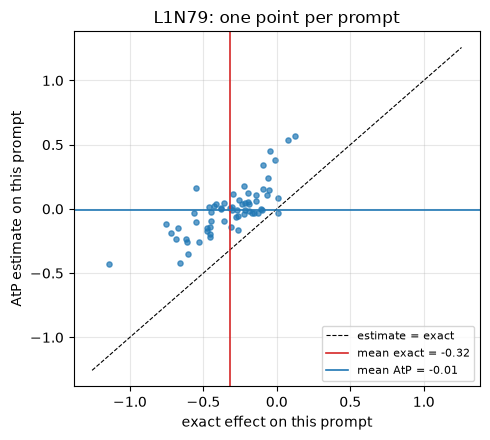

In [ ]:
# YOUR CODE HERE - diagnose the neuron found by bisection

<details><summary>Solution</summary>

```python
(layer, idx), _ = found[0]
name = f"blocks.{layer}.mlp.hook_post"
with t.no_grad():
    clean_act = model.run_with_cache(ioi.clean_tokens, names_filter=name)[1][name][:, :, idx]
    corrupt_act = model.run_with_cache(ioi.corrupt_tokens, names_filter=name)[1][name][:, :, idx]

change = (corrupt_act - clean_act).abs().mean(0)
str_tokens = [model.to_string(tok) for tok in ioi.clean_tokens[0]]
print("Largest mean |activation change| by position (tokens shown for prompt 0):")
for pos in change.argsort(descending=True)[:3].tolist():
    print(f"  position {pos:>2} {str_tokens[pos]!r:<9} change {change[pos]:.3f}  (clean mean {clean_act[:, pos].mean():+.3f}, corrupt mean {corrupt_act[:, pos].mean():+.3f})")


def patch_neuron(act: Tensor, hook) -> Tensor:
    act[:, :, idx] = corrupt_act
    return act


with t.no_grad():
    clean_metric = ioi.metric(model(ioi.clean_tokens), ioi.answers)
    patched_metric = ioi.metric(model.run_with_hooks(ioi.clean_tokens, fwd_hooks=[(name, patch_neuron)]), ioi.answers)
per_exact = (patched_metric - clean_metric).cpu()
neuron_pp = neuron_atp(model, ioi, per_prompt=True).cpu()
per_atp = neuron_pp[layer, idx]
utils.plot_per_prompt(per_exact, per_atp, f"L{layer}N{idx}")

abs_scores = neuron_pp.abs().mean(-1)
rank_abs = int((abs_scores > abs_scores[layer, idx]).sum()) + 1
print(
    f"corr = {t.corrcoef(t.stack([per_exact, per_atp]))[0, 1]:.2f}, exact < 0 on {(per_exact < 0).float().mean():.0%} of prompts, "
    f"mean exact = {per_exact.mean():+.3f}, mean AtP = {per_atp.mean():+.3f}, mean |AtP| = {per_atp.abs().mean():.3f}"
)
print(f"Rank by |mean AtP|: {int((abs_atp > abs_atp[layer, idx]).sum()) + 1:,}   rank by mean |per-prompt AtP|: {rank_abs:,}")
```
</details>

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Largest mean |activation change| by position (tokens shown for prompt 0):
  position 10 ' Mark'   change 2.551  (clean mean +2.390, corrupt mean -0.161)
  position 14 ' to'     change 0.044  (clean mean +0.159, corrupt mean +0.142)
  position  4 ' Mark'   change 0.023  (clean mean -0.134, corrupt mean -0.127)
corr = 0.77, exact < 0 on 94% of prompts, mean exact = -0.322, mean AtP = -0.006, mean |AtP| = 0.136
Rank by |mean AtP|: 1,222   rank by mean |per-prompt AtP|: 12</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**What the neuron does.** Almost all of the change happens at position 10, the second mention of the subject (S2, `' Mark'` in prompt 0). On clean prompts the neuron fires strongly
there (mean activation +2.39); on the ABC-corrupted prompts, where the name at that position is *not* a repeat, it's essentially off (−0.16). At the first mention of the same name
(position 4) it does nothing. So, on this data, it behaves like a duplicate-name detector in layer 1, which fits what we know about IOI: the circuit needs to know that S2 is a
repeated name, and the early "duplicate token" signal is where that starts.

**Why AtP misses it.** The answer is (b), the same as for `v4.11`. The per-prompt estimates track the exact effects (r = 0.77), but they sit about 0.3 above the diagonal, so they
straddle zero and average to −0.006, while the exact effect is negative on 94% of prompts and averages −0.32. Switching a neuron from +2.4 to −0.16 is a large, discrete change, and
a first-order Taylor expansion around the clean activation underestimates it by a roughly constant amount.

**What would have caught it.** Scoring by the mean of the *absolute* per-prompt estimates ranks this neuron 12th out of 36,864, well inside a budget of 100 verifications. So the
neuron-level false negative has the same cause, and the same cure, as the attention-node false negatives in section 3️⃣: AtP's per-prompt estimates carry the signal, and averaging
them signed throws it away.

The group test plus bisection found the neuron with no knowledge of any of this, which is the point of having a check on the unverified remainder: it catches failure modes you
didn't anticipate.
</details>

## Summary of 4️⃣

- For MLP neurons, exact patching is expensive and AtP is nearly free: one backward pass scores all 36,864 neurons.
- A budgeted workflow (rank cheaply, verify the top of the ranking exactly) finds neurons with much larger effects than random sampling.
- Group tests give a cheap check on the unverified remainder, as long as you remember that cancellation within a group and non-additive effects can fool them.
- When a group test flags something, adaptive group testing (bisection) can find the responsible neuron in about $2\log_2(\text{group size})$ patches. Here it found a layer-1 neuron with an exact effect of −0.32 that AtP had ranked 1,222nd, and the diagnosis was the same as for the attention nodes: per-prompt estimates that track the truth with an offset, which the mean-of-absolute-values aggregation catches.

# ☆ Bonus

## The paper's false-negative bound

Kramár et al. propose a more principled version of the group tests in section 4️⃣: sample random subsets of the unverified nodes, patch each subset, and use the distribution of
subset effects together with the nodes' AtP* scores to bound the largest effect any unverified node could have. Read section 3.3 of the paper, implement the procedure for the
attention nodes (where you have exact ground truth to check it against), and see whether the bound is ever violated.

## GradDrop where cancellation does happen

On IOI, gradient dropping contributed little beyond the per-prompt absolute-value aggregation. Can you find a task or model where it matters? Some ideas:

- Larger models, where more layers means more paths and more opportunities for cancellation (try `gpt2-medium` on IOI; exact patching of all attention nodes is still feasible).
- Tasks with known backup or self-repair behaviour: in [8.1] you saw name movers being compensated by backup heads, which is a natural source of cancelling indirect effects.
- Compare AtP*'s recall with and without dropping on each, as in the ablation table.

## AtP* with edges

[8.2] extended attribution patching from nodes to edges (EAP). Does the QK fix carry over to edges into query and key inputs? Implement it for EAP and check whether it changes the
circuits that EAP finds on IOI.

## Further reading

- Kramár, Lieberum, Shah & Nanda (2024), [*AtP\*: An efficient and scalable method for localizing LLM behaviour to components*](https://arxiv.org/abs/2403.00745). The paper this section follows; section 3 describes the failure modes and fixes, section 4 the evaluation on Pythia models.
- Neel Nanda (2023), [*Attribution Patching: Activation Patching At Industrial Scale*](https://www.neelnanda.io/mechanistic-interpretability/attribution-patching). The original blog post introducing attribution patching.
- Syed, Rager & Conmy (2023), [*Attribution Patching Outperforms Automated Circuit Discovery*](https://arxiv.org/abs/2310.10348). Edge attribution patching, which you implemented in [8.2].
- Hanna, Pezzelle & Belinkov (2024), [*Have Faith in Faithfulness*](https://arxiv.org/abs/2403.17806). EAP-IG, another way of reducing the linear approximation's errors.